In [ ]:
from dim_reduction import * 
import numpy as np 

# Exercice 1 

In [5]:
class PCAInverseTransform:
    def __init__(self, n_components):
        self.n_components = n_components
        self.components = None
        self.mean = None
        self.eigenvalues = None
        self.explained_variance_ratio_ = None

    def fit(self, X):
        self.mean = np.mean(X, axis=0)
        X_centered = X - self.mean # Step 1 

        cov_matrix = np.cov(X_centered, rowvar=False) # Step 2 

        eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix) # Step 3 

        sorted_idx = np.argsort(eigenvalues)[::-1] # Step 4 
        eigenvalues = eigenvalues[sorted_idx] # Step 4 
        eigenvectors = eigenvectors[:, sorted_idx] # Step 4 

        self.components = eigenvectors[:, : self.n_components].T
        self.eigenvalues = eigenvalues[: self.n_components]
        total_var = np.sum(eigenvalues)
        self.explained_variance_ratio_ = self.eigenvalues / total_var
        
        return self

    def transform(self, X):
        X_centered = X - self.mean
        return X_centered @ self.components.T

    def fit_transform(self, X):
        self.fit(X)
        return self.transform(X)

    def inverse_transform(self, X_reduced):
        return X_reduced @ self.components + self.mean

In [8]:
import numpy as np
from sklearn.datasets import fetch_openml

mnist = fetch_openml("mnist_784", version=1, as_frame=False,parser="liac-arff")
X = mnist.data[:5000].astype(float)
y = mnist.target[:5000].astype(int)

pca = PCAInverseTransform(n_components=200)
# Étape 1 : réduire les dimensions
X_reduced = pca.fit_transform(X)

print("Original :", X.shape)
print("Réduit :", X_reduced.shape)

# Étape 2 : reconstruire les images
X_reconstructed = pca.inverse_transform(X_reduced)

print("Reconstruit :", X_reconstructed.shape)

# Étape 3 : calculer l'erreur
mse = np.mean((X-X_reconstructed)**2)
print(mse)

Original : (5000, 784)
Réduit : (5000, 200)
Reconstruit : (5000, 784)
137.17268028859198


# Exercice 2 

Perplexity 5 : (5000, 2)


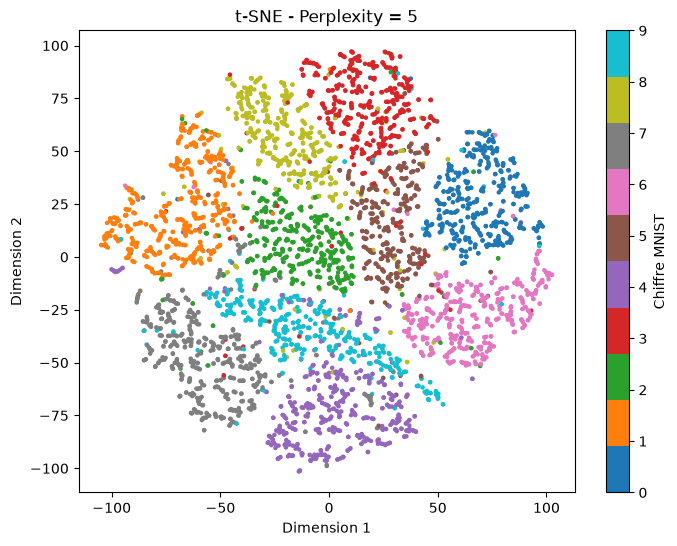

Perplexity 30 : (5000, 2)


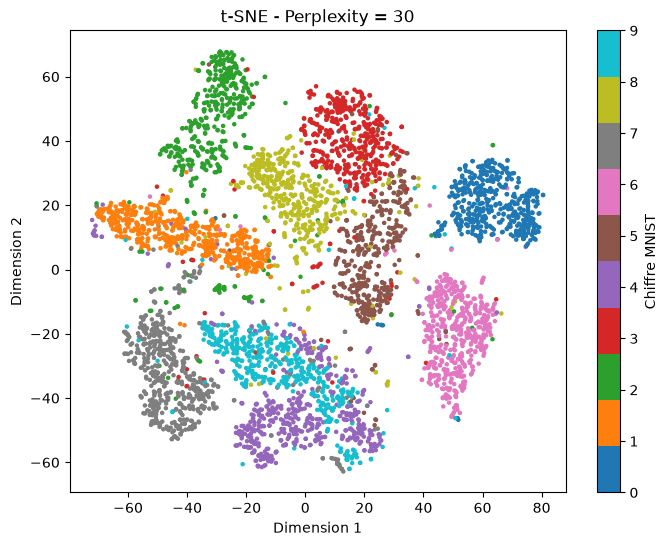

Perplexity 100 : (5000, 2)


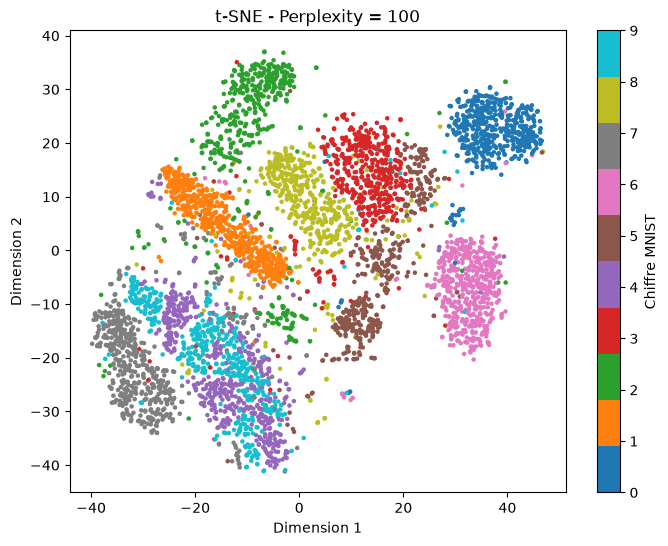

In [9]:
%matplotlib inline
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
perplexities = [5,30,100]

for p in perplexities :
    model = TSNE(perplexity=p,random_state=42)
    X_embedded = model.fit_transform(X)
    print(f"Perplexity {p} : {X_embedded.shape}")

    plt.figure(figsize=(8, 6))

    plt.scatter(
        X_embedded[:, 0],
        X_embedded[:, 1],
        c=y,
        cmap="tab10",
        s=5
    )

    plt.colorbar(label="Chiffre MNIST")
    plt.title(f"t-SNE - Perplexity = {p}")
    plt.xlabel("Dimension 1")
    plt.ylabel("Dimension 2")
    plt.show()

